# Humanoid robotics patents | Group 34
**Patent intelligence for Electrolux · Steps 0–3 · 2000–2022**

How quickly is humanoid robotics growing, which applicants account for that growth, and which firms lead once we account for citation influence, grants and international reach? We follow one set of DOCDB families from sector definition through firm scoring.

### Choice of team version

| Team material | Strength | How we use it |
|---|---|---|
| Imma's four PDF notebooks and v2 branch | A transparent sector rule, blind validation, and detailed checks on geographic coverage and score sensitivity. The PDF reports 37 relevant families in a blind sample of 40 from its 2,907-family sector. | Retain its emphasis on validation, denominators and alternative rankings. Its 92.5% precision estimate belongs to that rule. |
| Leo's tutorial2 and Thomas's earlier retrieval package | The former documents sector search and text analysis. The latter preserves broad retrieval and applicant analysis through the competitive landscape. | Use their retrieval and text signals as implemented in the final branch. |
| Mostafa's single notebook | A concise narrative for the client and a clear distinction between precision and recall. Its growth analysis reports 1,281 families through 2022. | Keep the question-led format. Its counts and rankings belong to a different cohort. |
| Final landscape branch, commit `a5805e2` | Ships the classified family records, cohort stamps, annual PATSTAT benchmarks and both global and EP firm metrics. | **Selected numerical baseline** for all four steps. The small holdout limits confidence in the sector boundary. |

**To rerun:** Place this notebook beside the supplied team ZIP or inside the extracted project folder. Use a Python 3 Jupyter kernel with pandas, NumPy and Matplotlib, then choose *Restart Kernel and Run All Cells*. The saved outputs can be read immediately. The notebook uses the team's frozen PROD extracts. A fresh database retrieval or model fit requires the original team's TIP pipeline.

[Course notebooks and project-work mapping](https://github.com/graziasveva/innovation-management-datascience26)

In [1]:
from pathlib import Path
import gzip
import hashlib
import io
import json
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Set SOURCE to a ZIP path or the extracted project root if it lives elsewhere.
SOURCE = None
name = "group34--Innovation_managment"
candidates = [Path.cwd(), Path.cwd() / name, Path.cwd() / (name + ".zip")]
if SOURCE is None:
    SOURCE = next((p for p in candidates if (p / "results/classification_manifest.json").is_file()
                   or (p.is_file() and p.suffix.lower() == ".zip")), None)
if SOURCE is None:
    raise FileNotFoundError("Place the team ZIP beside this notebook or set SOURCE above.")
source = Path(SOURCE)

def read_bytes(relative):
    if source.is_dir():
        return (source / relative).read_bytes()
    with zipfile.ZipFile(source) as archive:
        return archive.read(name + "/" + relative)

def table(relative, **kwargs):
    return pd.read_csv(io.BytesIO(read_bytes("results/" + relative)), float_precision="round_trip", **kwargs)

manifest = json.loads(read_bytes("results/classification_manifest.json"))
for folder in ["landscape/project_work", "companies/project_work", "value", "value/citations"]:
    stamp = read_bytes(f"results/{folder}/classification.json").decode().strip()
    assert stamp == manifest["analysis_scope_sha256"], f"Cohort mismatch in {folder}"
plt.rcParams.update({"figure.figsize": (8, 3.4), "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.3f}".format

## Step 0 · Define the sector and test the boundary

One observation represents one DOCDB family, so filing the same invention in several offices does not inflate sector volume. Thomas's broad PATSTAT PROD search admits walking robots, robot hands and joints, among other terms, and robotics classifications such as B25J. These routes also capture industrial manipulators and non-humanoid walking machines.

The strict rule requires **both** Leo's expanded text/code signal and a nonnegative classifier margin. The expanded rule admits dedicated body parts in a robotic context. The classifier uses representative titles and abstracts encoded by Patent SBERT and balanced logistic regression trained on 84 positive and 170 negative development labels. Missing margins and conflicting signals go to review. A strict family can have an unresolved subtype.

In [2]:
blob = read_bytes("results/classified_families.csv.gz")
assert hashlib.sha256(blob).hexdigest() == manifest["classification_sha256"]
cols = ["docdb_family_id", "leo_expanded_rule", "supervised_score", "category", "strict_scope"]
families = pd.read_csv(gzip.GzipFile(fileobj=io.BytesIO(blob)), usecols=cols)
strict = families.leo_expanded_rule & families.supervised_score.ge(manifest["sbert_threshold"])
assert families.docdb_family_id.is_unique and strict.equals(families.strict_scope)
assert strict.sum() == manifest["strict_scope"] and len(families) == manifest["family_count"]
print(f"{strict.sum():,} strict families from {len(families):,} candidates ({strict.mean():.2%})")
display(families.category.value_counts().rename("families").to_frame())
validation = table("holdout.csv")
display(validation)

3,526 strict families from 176,342 candidates (2.00%)


,families
category,
affine,118525
out_of_scope,27850
uncertain,26441
humanoid_unspecified,2723
dedicated_component,592
humanoid_platform,211


,method,reviewed,positives,selected,true_positives,precision,recall
0,Leo expanded,21,18,21,18,0.857,1.000
1,Supervised SBERT,21,18,18,16,0.889,0.889
2,Leo AND SBERT,21,18,18,16,0.889,0.889
3,Leo OR SBERT,21,18,21,18,0.857,1.000


The intersection recovered 16 of 18 relevant families and selected two false positives. Precision and recall were both 88.9% on the 21 held-out labels. Leo's rule selected every held-out family, so this sample cannot show whether combining the signals improves on SBERT alone. It also cannot measure recall outside the retrieved pool. Within the strict sector, 2,723 families have unresolved subtypes. Use the full sector for trend estimates and treat component-level conclusions more cautiously.

## Step 1 · How fast is the sector growing, and where?

We date a family by its earliest valid PATSTAT filing year, used as a priority-year proxy. The worldwide benchmark uses the same convention. Indexing both series to 100 in 2000 lets us compare growth across populations of very different sizes.

year,2000,2022,Annualised growth (%)
Humanoid,46,286,8.661
All PATSTAT,800986,2196024,4.691


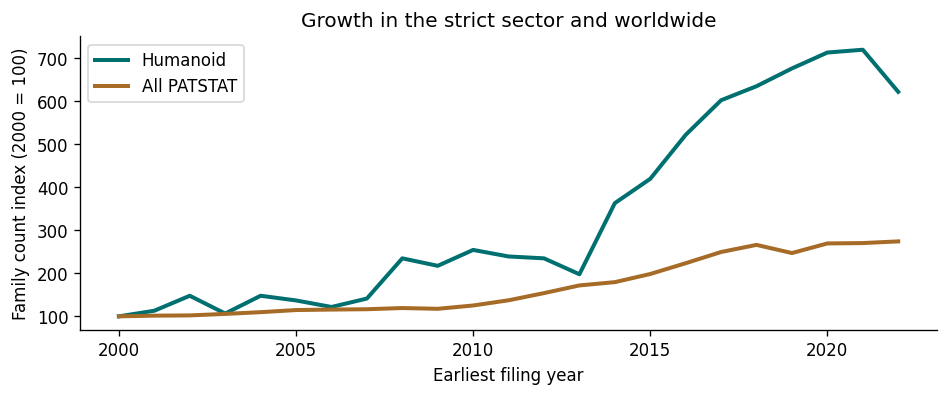

In [3]:
def sector_table(metric):
    data = table(f"landscape/project_work/sector_{metric}.csv")
    return data.loc[data.category.eq("strict")].drop(columns="category")

annual = sector_table("annual").set_index("year").sort_index()
assert annual.sector_families.sum() == strict.sum()
counts = annual[["sector_families", "patstat_families"]].rename(
    columns={"sector_families": "Humanoid", "patstat_families": "All PATSTAT"})
summary = counts.iloc[[0, -1]].T
summary["Annualised growth (%)"] = 100 * ((summary.iloc[:, 1] / summary.iloc[:, 0]) **
                                         (1 / (counts.index[-1] - counts.index[0])) - 1)
display(summary)
ax = (100 * counts / counts.iloc[0]).plot(color=["#006f70", "#a66b27"], linewidth=2.4)
ax.set(xlabel="Earliest filing year", ylabel="Family count index (2000 = 100)", title="Growth in the strict sector and worldwide")
plt.tight_layout()
plt.show()

In [4]:
technology = sector_table("technology")
leaders = (technology.sort_values("fractional_families", ascending=False)
           .groupby(["level", "period"]).head(1).sort_values(["level", "period"]))
display(leaders[["level", "period", "label", "share_of_coded_pct"]].reset_index(drop=True))
display(sector_table("offices").sort_values("applications", ascending=False).reset_index(drop=True))
geo = sector_table("countries").sort_values("fractional_families", ascending=False)
geo = geo.groupby(["period", "role"]).head(1)
display(sector_table("country_coverage").merge(geo, on=["period", "role"], validate="one_to_one")
        [["period", "role", "coverage_pct", "country", "share_of_known_pct"]])

,level,period,label,share_of_coded_pct
0,CPC subclass,2000-2007,B25J,41.036
1,CPC subclass,2008-2014,B25J,44.287
2,CPC subclass,2015-2022,B25J,47.630
3,WIPO field,2000-2007,Handling,65.524
4,WIPO field,2008-2014,Handling,63.224
5,WIPO field,2015-2022,Handling,56.796
6,WIPO sector,2000-2007,Mechanical engineering,76.240
7,WIPO sector,2008-2014,Mechanical engineering,77.032
8,WIPO sector,2015-2022,Mechanical engineering,80.765


,office_group,applications,families,applications_share_pct
0,CN,2216,2174,35.702
1,JP,994,951,16.014
2,US,910,797,14.661
3,Other,632,377,10.182
4,KR,528,499,8.507
5,WO,522,507,8.410
6,EP,405,349,6.525


,period,role,coverage_pct,country,share_of_known_pct
0,2000-2007,applicant,57.388,JP,51.790
1,2000-2007,inventor,57.388,JP,50.243
2,2008-2014,applicant,53.059,KR,39.039
3,2008-2014,inventor,52.809,KR,39.234
4,2015-2022,applicant,30.071,JP,25.911
5,2015-2022,inventor,27.059,JP,26.417


Annual volume rose from 46 to 286 families. Humanoid patenting grew about 6.2-fold against 2.7-fold for all PATSTAT families, even though the sector still represented only 0.013% of the 2022 total.

In 2015–2022, handling accounted for 56.8% of WIPO-coded family weight, and manipulators (B25J) accounted for 47.6% under CPC. Each coded family contributes one unit per scheme, split among its assignments. Robotics codes also helped retrieve the candidates, which partly explains their prominence.

China received 35.7% of the cohort's in-window applications. That measures filing destination. Applicant and inventor locations use fractional shares among families with a known country for that role. In 2015–2022, coverage fell to 30.1% for applicants and 27.1% for inventors. A country ranking from those records alone would give an incomplete picture of where invention occurred. The observed growth measures patenting activity. The data cannot quantify software, process know-how or inventions retained as trade secrets.

## Step 2 · Who competes, and which technologies are expanding?

Use harmonised applicant names and count each family once per distinct applicant. A jointly held family contributes one link to each owner. Concentration shares therefore use all applicant–family links as the denominator. The applicant universe includes companies, universities and individuals.

,applicants,CR4_pct,CR8_pct,HHI,HHI_equivalent_firms,CV_between_portfolios,Gini,Lotka_exponent
period,,,,,,,,
2000-2022,2171,8.131,13.341,0.004,273.695,2.633,0.517,1.456
2000-2004,288,19.620,27.057,0.018,56.432,2.026,0.485,1.258
2018-2022,881,13.197,18.940,0.007,135.218,2.348,0.462,1.442


,applicant,status,first_year,last_year,families
0,HONDA MOTOR CO LTD,incumbent,2000,2019,109
1,SEIKO EPSON CORPORATION,incumbent,2002,2022,107
2,UBTECH ROBOTICS CORP LTD,entrant,2016,2022,104
3,BEIJING INSTITUTE OF TECHNOLOGY,incumbent,2008,2022,92
8,CHANGZHOU UNIVERSITY,entrant,2015,2021,40
16,ZHEJIANG LAB,entrant,2019,2022,31


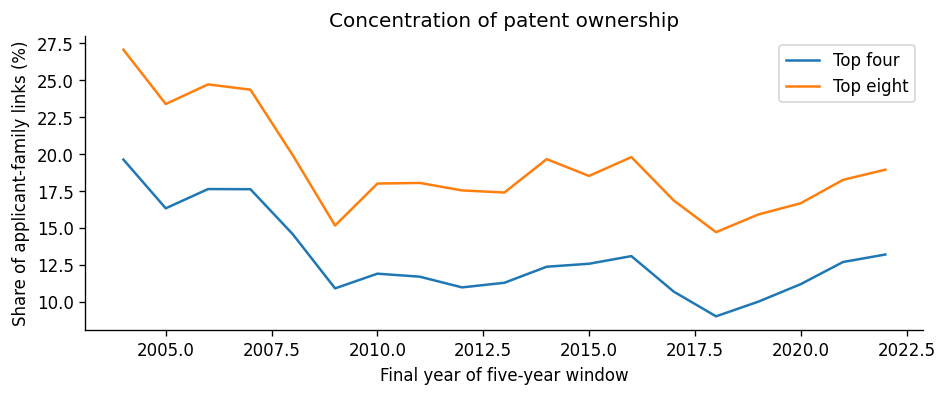

In [5]:
def competition(metric):
    return table(f"companies/project_work/competition_{metric}.csv")

owners = competition("applicants").sort_values("families", ascending=False)
concentration = competition("concentration").set_index("period")
shares = owners.families / owners.families.sum()
assert np.isclose(shares.pow(2).sum(), concentration.loc["2000-2022", "HHI"])
display(concentration.loc[["2000-2022", "2000-2004", "2018-2022"]])
display(owners.groupby("status").head(3)[["applicant", "status", "first_year", "last_year", "families"]])
windows = concentration.drop("2000-2022").copy()
windows.index = windows.index.str[-4:].astype(int)
ax = windows[["CR4_pct", "CR8_pct"]].rename(columns={"CR4_pct": "Top four", "CR8_pct": "Top eight"}).plot()
ax.set(xlabel="Final year of five-year window", ylabel="Share of applicant-family links (%)", title="Concentration of patent ownership")
plt.tight_layout()
plt.show()

In [6]:
dynamics = competition("entrants_exits").set_index("year")
display(dynamics.loc[[2015, 2019, 2022], ["active_applicants", "new_applicants",
        "entrant_family_share_pct", "last_seen_applicants", "disappearance_pct"]])
growth = competition("subfield_growth")
display(growth.nlargest(6, "change_families").reset_index(drop=True))

,active_applicants,new_applicants,entrant_family_share_pct,last_seen_applicants,disappearance_pct
year,,,,,
2015,152,104,46.632,93.000,61.184
2019,221,131,41.801,148.000,66.968
2022,233,136,43.357,NaN,NaN


,main_group,2013-2017,2018-2022,change_families,change_pct
0,B25J9/00,365.000,700.000,335.000,91.781
1,B62D57/00,218.000,485.000,267.000,122.477
2,G05D1/00,23.000,138.000,115.000,500.000
3,B25J13/00,111.000,211.000,100.000,90.090
4,B25J19/00,125.000,212.000,87.000,69.600
5,B25J17/00,91.000,153.000,62.000,68.132


The top four applicants' share fell from 19.6% in 2000–2004 to 13.2% in 2018–2022. Honda led on cumulative families (109), but UBTECH, first observed in 2016, reached 104. An entrant is an applicant first seen in this sector from 2015 onward. In 2022, 43.4% of families included a first-time sector applicant. Last appearances require three later years of observation, so the final three years have no exit estimate.

B25J9/00 (programme-controlled manipulators) added 335 families between the two five-year windows. G05D1/00 (vehicle position or course control) grew faster in percentage terms, from 23 to 138. Families can appear in several CPC main groups. Growth in a main group does not isolate a single product market.

### PEST implications for Electrolux

| Force | Question raised by the evidence |
|---|---|
| Political | China's robotics policy makes it worth examining whether local programmes influence filing incentives. The filing-office counts alone cannot establish that effect. [International Federation of Robotics](https://ifr.org/ifr-press-releases/news/china-makes-ai-powered-robots-core-of-national-strategy) |
| Economic | Lower patent concentration and UBTECH's entry widen the pool of possible partners. What do their unit costs and service capabilities look like at pilot scale? |
| Social | Population ageing gives household assistance a plausible use case. Would intended users accept the cost and safety trade-offs of a mobile manipulator at home? [Eurostat](https://ec.europa.eu/eurostat/statistics-explained/index.php/Population_structure_and_ageing) |
| Technological | Manipulation and navigation both grew. For an appliance-handling pilot, compare grasp reliability and safe movement in constrained spaces alongside patent breadth. |

The policy and demographic sources are context drawn from the team's Step 2 reading. These implications are hypotheses for client diligence.

## Step 3 · Which firms lead on patent portfolio value?

Score companies on four dimensions. **Volume** averages annual portfolio shares. **Influence** counts distinct forward family citations in a complete five-year window. **Success** uses the share of eligible applications recorded as granted within each family. **Reach** counts distinct national or regional filing offices. Grant status can still change, and office count is a proxy for intended protection.

For influence, success and reach, divide each family value by the reference mean in its year and then average available ratios for the firm. Use either the strict sector or a fixed worldwide PATSTAT sample of 500 families per year. Volume uses full annual population counts. Reference means require at least five observations and a positive mean. Annual adjustment addresses age effects while leaving technology-field differences. The EP scenario restricts families and benchmarks to EP filers and measures EP grant success.

A firm needs at least three families and data for every component under both references. Rank each component in descending order with average ranks for ties. For N eligible firms, combine component ranks r with weights w as **100 × (N + 1) × Σ[w / (N + r)]**. The baseline weights are 25% each.

In [7]:
components = ["volume", "influence", "success", "reach"]
weights = {"equal": [.25, .25, .25, .25], "influence_first": [.15, .40, .20, .25],
           "volume_first": [.40, .20, .20, .20]}
def score_firms(scenario, reference):
    metrics = table(f"value/{scenario}_firm_metrics.csv").set_index("applicant")
    required = [f"{k}_{ref}" for ref in ["sector", "patstat"] for k in components]
    eligible = metrics.loc[metrics.families.ge(3)].dropna(subset=required)
    fields = [f"{k}_{reference}" for k in components]
    ranks = eligible[fields].rank(ascending=False, method="average")
    n = len(eligible)
    result = eligible[["families", "families_with_full_5y", *fields]].copy()
    for label, w in weights.items():
        score = 100 * (n + 1) * (1 / (n + ranks)).mul(w, axis=1).sum(axis=1)
        result[label] = score.round(12).rank(ascending=False, method="min").astype(int)
        if label == "equal":
            result["score"] = score
    saved = table(f"value/{scenario}_ranking.csv").set_index("applicant").loc[result.index]
    assert set(result.nsmallest(3, "equal").index) == set(saved.nsmallest(3, f"rank_{reference}").index)
    return result.sort_values(["equal", "families"], ascending=[True, False])

coverage = pd.concat([table(f"value/{s}_coverage.csv") for s in ["global", "ep"]])
display(coverage[["scenario", "families_in_scenario", "families_with_full_5y_window", "firms_scored"]])
global_rank = score_firms("global", "patstat")
display(global_rank.head(8))
comparison = pd.concat({(s, ref): score_firms(s, ref)["equal"].loc[lambda r: r <= 3]
                        for s in ["global", "ep"] for ref in ["patstat", "sector"]},
                       names=["portfolio", "benchmark", "applicant"])
display(comparison.rename("rank").reset_index())
display(table("value/citations/profile_directions.csv"))

,scenario,families_in_scenario,families_with_full_5y_window,firms_scored
0,global,3526,2658,103
0,ep,364,281,21


,families,families_with_full_5y,volume_patstat,influence_patstat,success_patstat,reach_patstat,equal,score,influence_first,volume_first
applicant,,,,,,,,,,
HONDA MOTOR CO LTD,109,108,0.000,2.945,1.679,1.849,1,88.627,4,1
UNIVERSAL ROBOTS A/S,14,6,0.000,5.806,1.518,3.103,2,87.411,1,5
TENCENT TECHNOLOGY SHENZHEN CO LTD,21,3,0.000,3.934,1.742,1.893,3,86.321,3,4
BOSTON DYNAMICS INC,18,13,0.000,3.657,1.540,2.125,4,85.478,6,6
PANASONIC CORPORATION,31,31,0.000,3.287,1.505,1.746,5,84.995,9,2
CLOUDMINDS ROBOTICS CO LTD,3,3,0.000,6.951,2.113,2.454,6,84.532,2,21
FANUC CORPORATION,14,8,0.000,2.852,1.471,3.027,7,83.990,10,11
UBTECH ROBOTICS CORP LTD,104,42,0.000,3.370,1.634,1.136,8,83.706,11,3


,portfolio,benchmark,applicant,rank
0,global,patstat,HONDA MOTOR CO LTD,1
1,global,patstat,UNIVERSAL ROBOTS A/S,2
2,global,patstat,TENCENT TECHNOLOGY SHENZHEN CO LTD,3
3,global,sector,PANASONIC CORPORATION,1
4,global,sector,HONDA MOTOR CO LTD,2
5,global,sector,TENCENT TECHNOLOGY SHENZHEN CO LTD,3
6,ep,patstat,ALDEBARAN ROBOTICS,1
7,ep,patstat,HONDA MOTOR CO LTD,2
8,ep,patstat,SEIKO EPSON CORPORATION,3
9,ep,sector,HONDA MOTOR CO LTD,1


,direction,eligible_families,total,applicant,office,examination,applicant_only,office_only,both,other_or_unknown_only
0,incoming_5y,2658,14566,1195,13786,402,780,13371,415,0
1,outgoing,3526,31465,7469,26963,1298,4496,23990,2973,6


Recomputing from the exported firm metrics reproduces the three leaders in all four comparisons. Global scores using the sector benchmark differ from the saved scores by up to 0.071 points. The tables here use the recomputed values.

**Client reading.** Honda leads the worldwide-benchmarked global ranking, with 108 of its 109 families observed for a full citation window. Universal Robots ranks second and moves to first when influence receives 40% weight, but only six of its 14 families have complete citation windows. Its influence estimate therefore rests on fewer inventions. Panasonic leads when the same global portfolios are benchmarked against the humanoid sector. Aldebaran leads the worldwide-benchmarked EP comparison, which covers 21 eligible firms versus 103 globally.

Of the 31,465 outgoing citation links, 23,990 are recorded only by an office. A reference can reflect an examiner's prior-art search, so citation counts alone give limited evidence of direct knowledge transfer. For Electrolux, Honda is a starting point for examining a sustained patent position. Universal Robots merits a closer look at the particular inventions driving its influence. The ranking measures observed patent portfolios through the study window and supplies no monetary valuation or evidence of current product readiness.

**Source trail.** All numerical inputs come from the supplied Group 34 archive. The sector decision and holdout are in `results/`, the description and competition estimates in the two `project_work/` folders, and the firm metrics, annual references and citation profiles in `results/value/`. The team's retrieval, classification, concentration and annual scoring implementations are under `src/`. The four PDF exports document the alternative rule-based analysis. Its results are quoted only where explicitly identified.